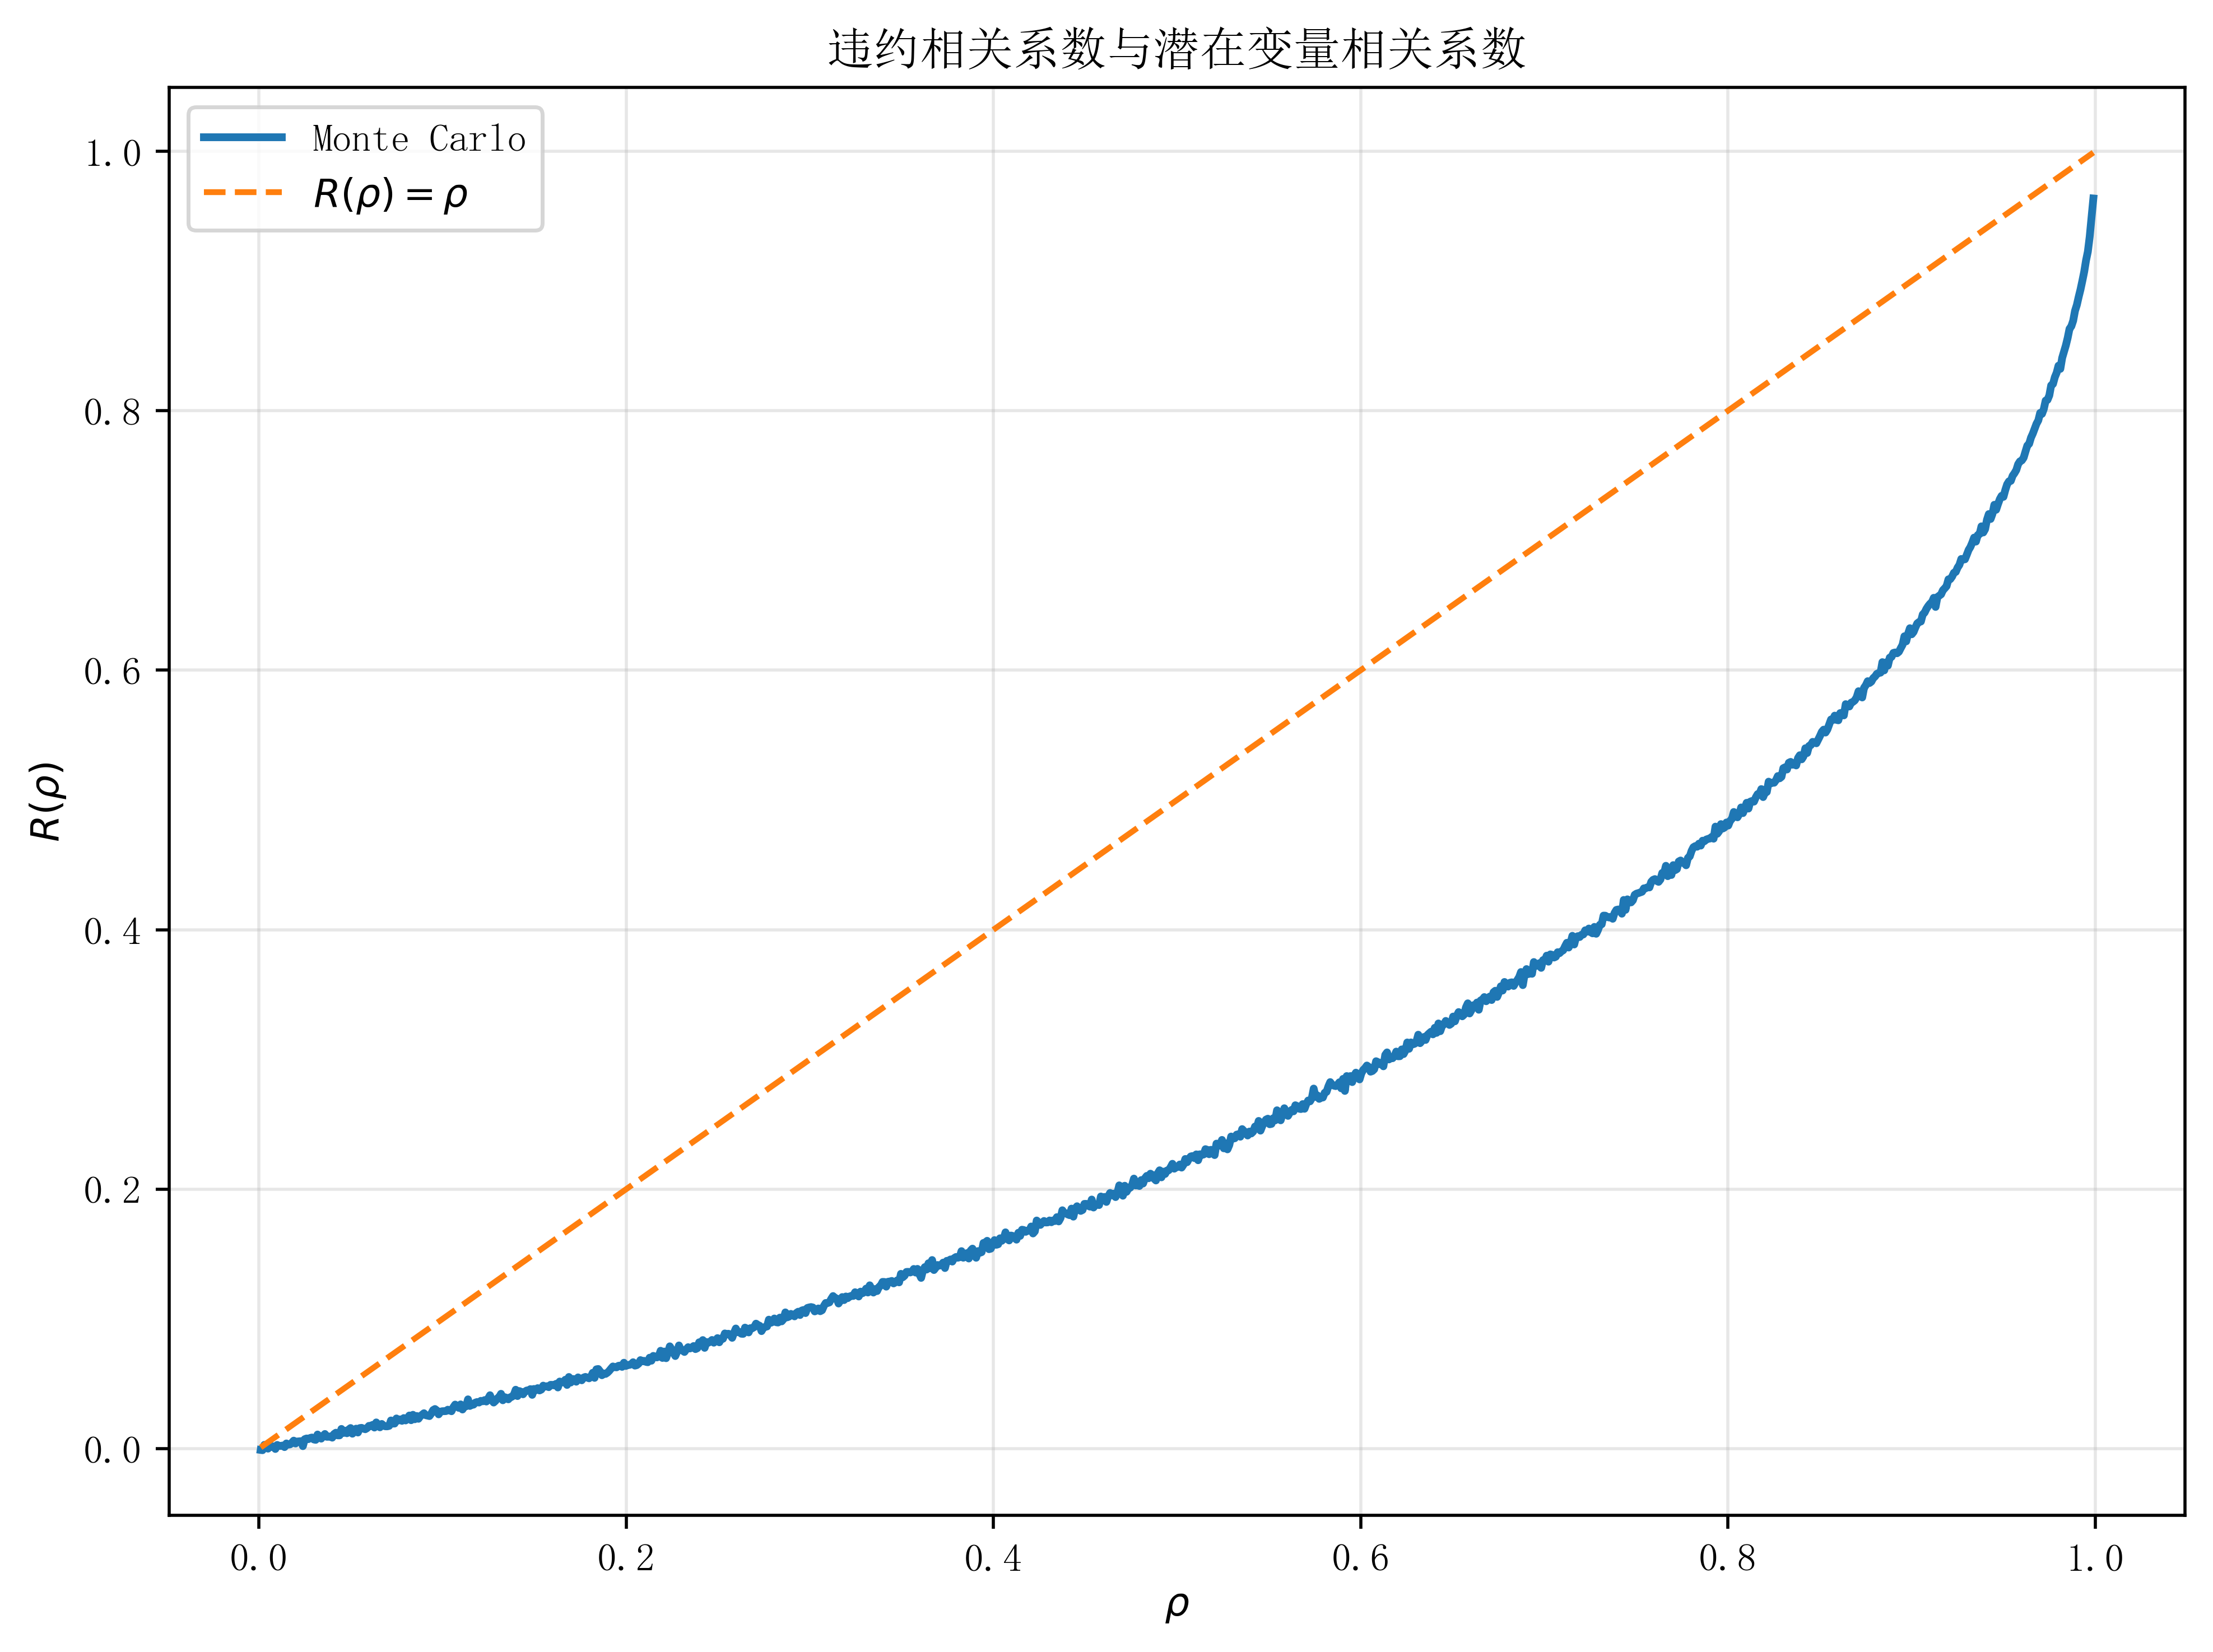

In [6]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Simsun'] 

np.random.seed(123)

a = -1.535

rho_grid = np.linspace(0.001, 0.999, 1000)

R_sim = []

N = 500000

for rho in rho_grid:

    Sigma = np.array([
        [1, rho],
        [rho, 1]
    ])

    # 模拟二维正态变量
    X = np.random.multivariate_normal(
        mean=[0, 0],
        cov=Sigma,
        size=N
    )

    R1 = X[:, 0]
    R2 = X[:, 1]

    # 生成违约指标
    d1 = (R1 < a).astype(int)
    d2 = (R2 < a).astype(int)

    # 样本相关系数
    corr = np.corrcoef(d1, d2)[0, 1]

    R_sim.append(corr)


plt.figure(figsize=(8, 6), dpi=500)

plt.plot(
    rho_grid,
    R_sim,
    linewidth=2,
    label="Monte Carlo"
)

plt.plot(
    rho_grid,
    rho_grid,
    linestyle="--",
    label=r"$R(\rho)=\rho$"
)

plt.xlabel(r"$\rho$")
plt.ylabel(r"$R(\rho)$")

plt.title("违约相关系数与潜在变量相关系数")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()